In [2]:
import numpy as np
import pandas as pd

In [3]:
data = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"
!wget -P /home/asus/Machine-Learning/ml-zoomcamp-2k26/module_2_regression/datasets/ $data

--2026-09-29 19:16:02--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘/home/asus/Machine-Learning/ml-zoomcamp-2k26/module_2_regression/datasets/car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K   555KB/s    in 1.1s    

2026-09-29 19:16:04 (555 KB/s) - ‘/home/asus/Machine-Learning/ml-zoomcamp-2k26/module_2_regression/datasets/car_fuel_efficiency_2026.csv’ saved [635180/635180]



In [3]:
df = pd.read_csv("/home/asus/Machine-Learning/ml-zoomcamp-2k26/module_2_regression/datasets/car_fuel_efficiency_2026.csv")
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

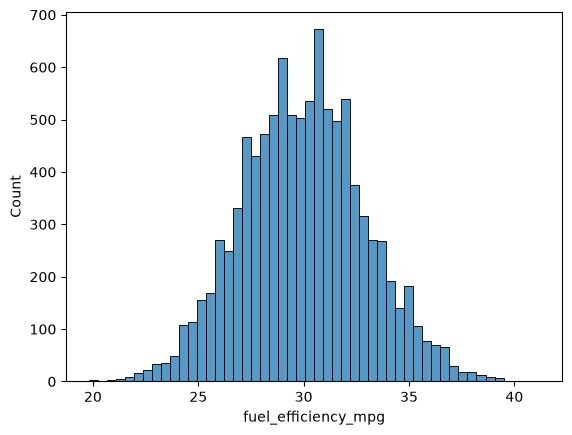

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.histplot(df.fuel_efficiency_mpg, bins = 50)

In [6]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

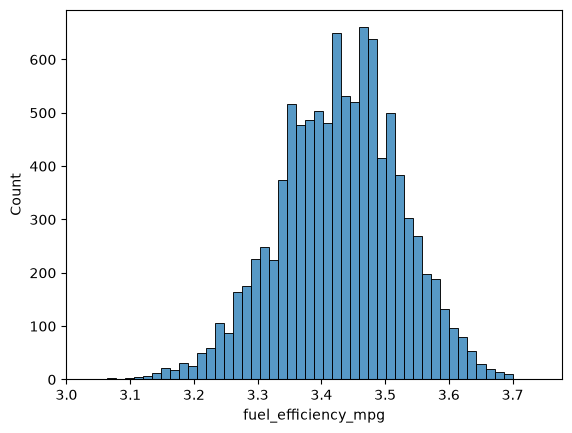

In [7]:
efficiency_logs = np.log1p(df.fuel_efficiency_mpg)
sns.histplot(efficiency_logs, bins = 50)

In [8]:
# filling NaN values with median
cols = list(df.columns[df.isnull().sum() > 0])

def fill_na():
    for col in cols:
        df[col] = df[col].fillna(df[col].median())
fill_na()
df.isnull().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

In [9]:
df.head()


,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,18.9,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,18.9,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [10]:
n = len(df)

n_train = int(0.6 * n)
n_val = int(0.2 * n)
n_test = n - (n_train + n_val)

print(n, "\n", n_train, "\n", n_val, "\n", n_test)

10000 
 6000 
 2000 
 2000


In [11]:
df_train = df.iloc[:n_train]
df_val = df.iloc[n_train : n_train + n_val]
df_test = df.iloc[n_train + n_val:]


df_train

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,18.9,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,18.9,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
5995,1981,USA,Gasoline,Rear-wheel drive,3,1970,6,254.0,4190,20.0,23.6
5996,2020,USA,Gasoline,All-wheel drive,3,2180,6,266.0,4400,17.6,29.8
5997,1995,USA,Gasoline,Front-wheel drive,4,2100,6,251.0,4000,19.8,27.7
5998,2016,USA,Gasoline,All-wheel drive,4,2240,6,265.0,4540,19.7,27.5


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

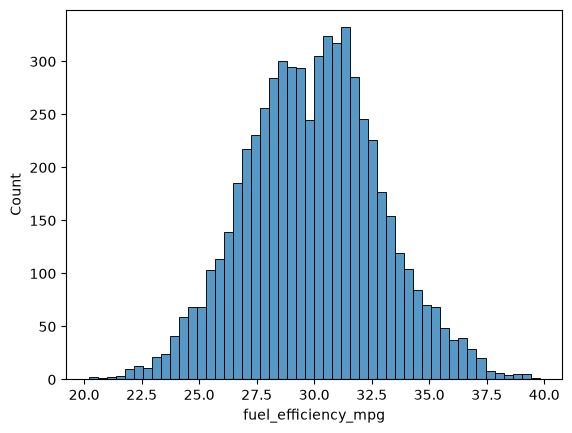

In [12]:
sns.histplot(df_train.fuel_efficiency_mpg, bins = 50)

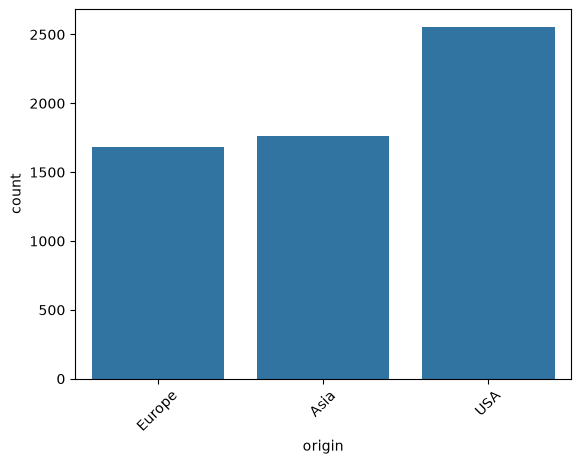

origin
USA       0.426000
Asia      0.293833
Europe    0.280167
Name: proportion, dtype: float64

In [13]:
sns.countplot(data=df_train, x="origin")
plt.xticks(rotation=45)
plt.show()

df_train["origin"].value_counts(normalize=True)

In [14]:
idx = np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)

df_train = df.iloc[:n_train]
df_val = df.iloc[n_train : n_train + n_val]
df_test = df.iloc[n_train + n_val:]


df_train

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,18.9,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,18.9,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
5995,1981,USA,Gasoline,Rear-wheel drive,3,1970,6,254.0,4190,20.0,23.6
5996,2020,USA,Gasoline,All-wheel drive,3,2180,6,266.0,4400,17.6,29.8
5997,1995,USA,Gasoline,Front-wheel drive,4,2100,6,251.0,4000,19.8,27.7
5998,2016,USA,Gasoline,All-wheel drive,4,2240,6,265.0,4540,19.7,27.5


In [15]:
print(df["origin"].value_counts(normalize = True))
print(df_train["origin"].value_counts(normalize=True))
print(df_val["origin"].value_counts(normalize=True))
print(df_test["origin"].value_counts(normalize=True))

# you can see the similar kinda distribution in all sections

origin
USA       0.4202
Asia      0.2994
Europe    0.2804
Name: proportion, dtype: float64
origin
USA       0.426000
Asia      0.293833
Europe    0.280167
Name: proportion, dtype: float64
origin
USA       0.4050
Asia      0.3115
Europe    0.2835
Name: proportion, dtype: float64
origin
USA       0.418
Asia      0.304
Europe    0.278
Name: proportion, dtype: float64


In [16]:
# result values for trainig and evaluation
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [17]:
y_train[20]

np.float64(30.1)

In [18]:
def test_linear_regression(w):
    xi = [2130, 258, 4490]
    
    
    pred = w[0]

    for val in range(len(xi)):
        pred += xi[val]*w[val+1]
    print(pred, y_train[4])

w = [0, 1, 1, 1]
test_linear_regression(w)
    

6878 31.0


<Axes: xlabel='horsepower'>

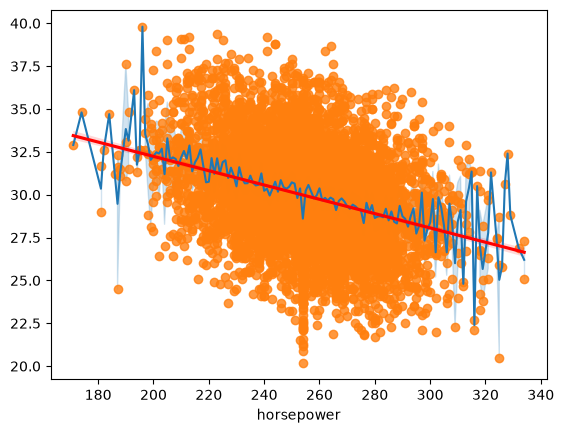

In [19]:
sns.lineplot(data=df_train, x='horsepower',
                y=y_train)
sns.regplot(
    data=df_train,
    x='horsepower',
    y=y_train,
    line_kws={'color': 'red'}
)

In [20]:
from scipy.stats import linregress

result = linregress(df_train['horsepower'], y_train)

w_horsepower = result.slope
w0 = result.intercept

print("Weight:", w_horsepower)
print("Intercept:", w0)

Weight: -0.04173337412294902
Intercept: 40.5818391601966


In [21]:
df['model_year'].max()

np.int64(2024)

In [23]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'acceleration']
X_train = df_train[base].values

def prepare_X(df):
    df = df.copy()

    df['age'] = df['model_year'].max() - df['model_year']
    features = base + ['age']
    X = df[features].values
    return X

def weight_prediction():
    pass

X_train = list(prepare_X(df_train))
X_train

[array([2180. ,  243. , 3870. ,   18.9,   18. ]),
 array([2390. ,  272. , 4210. ,   18.9,   16. ]),
 array([2320. ,  267. , 4240. ,   17.3,   28. ]),
 array([2130. ,  258. , 4490. ,   18.7,   35. ]),
 array([2580. ,  304. , 4510. ,   17.5,   30. ]),
 array([2290. ,  266. , 4260. ,   18.8,   17. ]),
 array([2270. ,  250. , 4310. ,   21.7,   32. ]),
 array([2370. ,  279. , 4090. ,   17.4,   19. ]),
 array([2330. ,  251. , 4230. ,   19.5,   27. ]),
 array([2330. ,  280. , 4620. ,   17.7,   20. ]),
 array([2410. ,  254. , 4420. ,   19.5,   46. ]),
 array([2240. ,  250. , 3980. ,   16.7,   28. ]),
 array([2370. ,  254. , 4390. ,   20.7,   41. ]),
 array([2440. ,  277. , 4790. ,   20.2,    0. ]),
 array([1900. ,  202. , 4070. ,   18.7,    9. ]),
 array([2170.,  226., 3950.,   18.,   17.]),
 array([2.28e+03, 2.34e+02, 4.75e+03, 2.01e+01, 3.00e+00]),
 array([2.54e+03, 2.99e+02, 4.69e+03, 1.79e+01, 3.00e+00]),
 array([2490. ,  264. , 4230. ,   17.7,   29. ]),
 array([2320. ,  251. , 4410. ,   1

In [26]:
def weight_prediction(X, y):
    features = base + ['age']

    weights = []
    for i, feature in enumerate(features):
        result = linregress(X[:,i], y)
        weights.append(result.slope)
    weights = np.array(weights)

    w0 = np.mean(y - X@weights)

    return w0, weights
w0, w = weight_prediction(X_train, y_train)
print(w0)
print(w)
    

82.46229499874657
[-0.00551501 -0.04173337 -0.00473774 -0.34667954 -0.10203659]


In [28]:
y_pred = w0 + X_train @ w
print(y_pred)

[33.574391   29.7992111  29.58204483 ... 31.63140445 29.8940906
 27.7477947 ]


<Axes: ylabel='Count'>

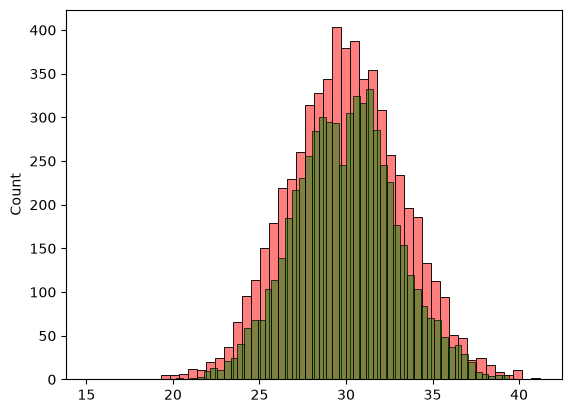

In [29]:
sns.histplot(y_pred, color = 'red', bins=50, alpha=0.5)
sns.histplot(y_train, color = "green", bins=50, alpha=0.5)

In [31]:
def rmse(y_pred, y_train):
    val = (y_pred - y_train) ** 2
    val = val.mean()
    return np.sqrt(val)

print(rmse(y_pred, y_train))

2.7990271252689145


2.7242300262073558


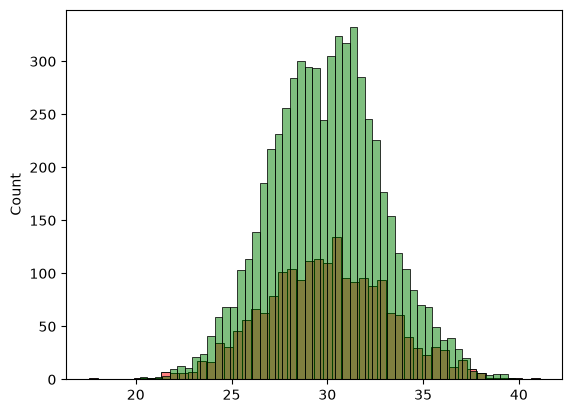

In [32]:
# now validate this model on validation dataset

X_val = prepare_X(df_val)
y_pred = w0 + X_val @ w

sns.histplot(y_pred, color = 'red', bins=50, alpha=0.5)
sns.histplot(y_train, color = "green", bins=50, alpha=0.5)

print(rmse(y_pred, y_val))

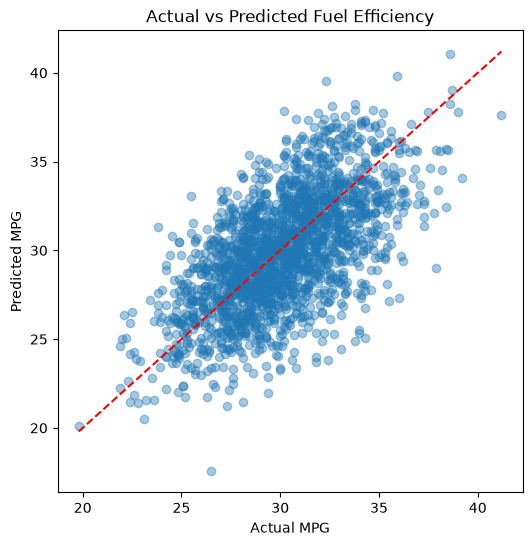

In [33]:
# actual vs predicted:

def plot(y, y_pred):
    plt.figure(figsize=(6, 6))

    plt.scatter(y, y_pred, alpha=0.4)
    
    plt.plot(
        [y.min(), y.max()],
        [y.min(), y.max()],
        'r--'
    )
    
    plt.xlabel("Actual MPG")
    plt.ylabel("Predicted MPG")
    plt.title("Actual vs Predicted Fuel Efficiency")
    
    plt.show()
plot(y_val, y_pred)

In [39]:
df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop = True)

y_full_train = np.concatenate([y_train, y_val])

X_full_train = prepare_X(df_full_train)

w0, w = weight_prediction(X_full_train, y_full_train)

y_pred = w0 + X_full_train@w

rmse(y_pred, y_full_train)

np.float64(2.7961955083550594)

In [41]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test@w
rmse(y_pred, y_test)

np.float64(2.918566067161895)

In [58]:
def MPG_prediction(val):
    df = val.to_frame().T
    
    X_test = prepare_X(df)
    y_pred = w0 + X_test @ w
    return y_pred[0]

print(MPG_prediction(df_test.iloc[5]))
print(pd.DataFrame(y_test).iloc[5].reset_index(drop = True))

30.060758280083057
0    28.8
Name: 5, dtype: float64


In [ ]:
df_te